In [1]:
import pandas as pd 
import numpy as np 
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv("ecg.csv")

X=df.iloc[:,:-1].values
y=df.iloc[:,-1]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
le=LabelEncoder()
y=le.fit_transform(y)
print(y)

[1 1 1 ... 0 0 0]


In [3]:
print(le.classes_)

[0. 1.]


In [4]:
normal = X_train[y_train == 1]
scaler = StandardScaler()
normal = scaler.fit_transform(normal)
X_test = scaler.transform(X_test)

In [5]:
model=keras.Sequential([

layers.Input(shape=(X.shape[1],)),
layers.Dense(32, activation="relu"),
layers.Dense(X.shape[1], activation="linear")

])
model.compile(optimizer="adam", loss="mse")

model.fit(normal, normal, epochs=10, batch_size=32)




Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8047
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3758
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2687
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2234
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1949
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1753
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1611
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1502
Epoch 9/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1418
Epoch 10/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1352


In [6]:
# 9. Calculate threshold
output = model.predict(normal)
error = np.mean((normal - output)**2, axis=1)
threshold = np.percentile(error, 95)

# 10. Test on unseen ECG
result = model.predict(X_test)
test_error = np.mean((X_test - result)**2, axis=1)

# 11. Detect anomalies
for i in range(5):
    if test_error[i] > threshold:
        print("Anomaly Detected")
    else:
        print("Normal ECG")

print("Actual labels:", y_test[:5])

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Normal ECG
Anomaly Detected
Normal ECG
Normal ECG
Normal ECG
Actual labels: 84      1.0
4374    0.0
1497    1.0
653     1.0
877     1.0
Name: 1.0, dtype: float64


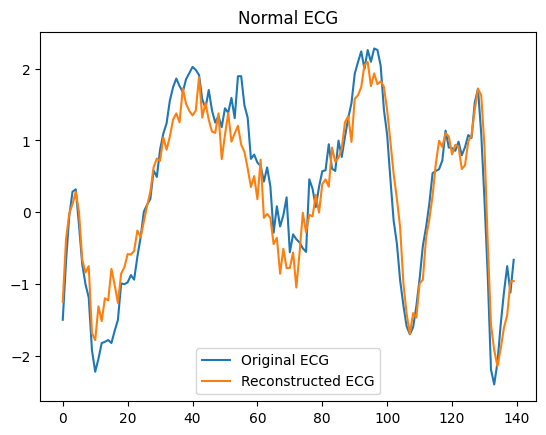

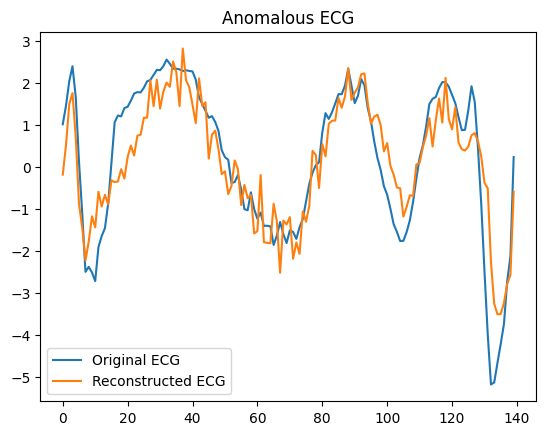

In [7]:

import matplotlib.pyplot as plt

# Normal ECG
plt.plot(X_test[y_test == 1][0], label="Original ECG")
plt.plot(result[y_test == 1][0], label="Reconstructed ECG")
plt.title("Normal ECG")
plt.legend()
plt.show()

# Anomalous ECG
plt.plot(X_test[y_test == 0][0], label="Original ECG")
plt.plot(result[y_test == 0][0], label="Reconstructed ECG")
plt.title("Anomalous ECG")
plt.legend()
plt.show()
